# Blind source separation using FastICA: scikit-learn vs Moxie

**Reference example:** `../scikit-learn/examples/decomposition/plot_ica_blind_source_separation.py` at scikit-learn
`4358542a1bd39af2e7e1cbace8b9fed067473c5b`
([rendered gallery page](https://scikit-learn.org/dev/auto_examples/decomposition/plot_ica_blind_source_separation.html)).

**Scenario:** three synthetic sources (sine, square, sawtooth; 2000 samples, Gaussian noise, `np.random.seed(0)`)
are mixed by a fixed 3x3 matrix. `FastICA(n_components=3, whiten="arbitrary-variance")` recovers the sources and the
mixing matrix (the example asserts `X == S_ @ A_.T + mean_`); `PCA(n_components=3)` is shown as the failing
orthogonal alternative.

**Adaptations:**
- The data are generated in Python exactly as in the example and shared with the Mojo cell.
- The example's FastICA uses `random_state=None`, so sklearn draws `w_init = normal(size=(3, 3))` from NumPy's
  global RandomState after the noise draw. The notebook captures that same draw (saving and restoring the global
  state, so the official call still runs unchanged and draws it again) and passes it to Moxie as `w_init`.
  Moxie's `random_state=None` uses its own entropy stream and cannot read Python's global RNG (documented in
  `families/decomposition/docs/fastica.md`).
- Extra checks on the same data: the `fastica` function, `algorithm="deflation"`, `fun="exp"`/`"cube"`,
  `whiten="unit-variance"` with `whiten_solver="eigh"`, `transform`/`inverse_transform` and a Float32 fit.

**Determinism:** deterministic given the captured `w_init`; results are compared numerically (no permutation or
sign matching is needed because both implementations start from the same matrix and use the same sign rules).

In [1]:
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "notebooks/_support/moxie_nb.py").exists())
sys.path.insert(0, str(ROOT / "notebooks/_support"))
%load_ext moxie_nb
nb = moxie_nb.Session("decomposition/plot_ica_blind_source_separation")

## 1. scikit-learn (Python reference)

sklearn n_iter_: 3 | mixing_:
 [[ 45.345678    46.05987087 -42.44766492]
 [ 88.66888771  44.06569318 -21.12305727]
 [ 44.60803174  91.78730847 -61.64451097]]


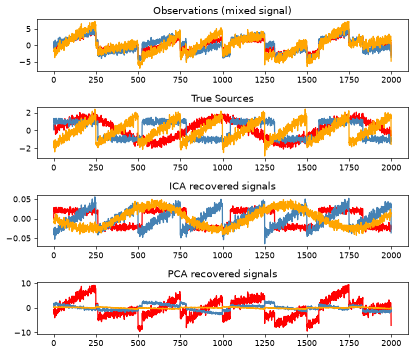

In [2]:
import matplotlib.pyplot as plt
import numpy as np
from scipy import signal

np.random.seed(0)
n_samples = 2000
time = np.linspace(0, 8, n_samples)

s1 = np.sin(2 * time)  # Signal 1 : sinusoidal signal
s2 = np.sign(np.sin(3 * time))  # Signal 2 : square signal
s3 = signal.sawtooth(2 * np.pi * time)  # Signal 3: saw tooth signal

S = np.c_[s1, s2, s3]
S += 0.2 * np.random.normal(size=S.shape)  # Add noise
S /= S.std(axis=0)  # Standardize data
A = np.array([[1, 1, 1], [0.5, 2, 1.0], [1.5, 1.0, 2.0]])  # Mixing matrix
X = np.dot(S, A.T)  # Generate observations

# Capture the w_init that FastICA(random_state=None) is about to draw from the global RNG.
_state = np.random.get_state()
w_init = np.random.normal(size=(3, 3))
np.random.set_state(_state)

from sklearn.decomposition import PCA, FastICA, fastica

ica = FastICA(n_components=3, whiten="arbitrary-variance")
S_ = ica.fit_transform(X)  # Reconstruct signals
A_ = ica.mixing_  # Get estimated mixing matrix
assert np.allclose(X, np.dot(S_, A_.T) + ica.mean_)

pca = PCA(n_components=3)
H = pca.fit_transform(X)  # Reconstruct signals based on orthogonal components

# The captured draw reproduces the official run exactly.
check = FastICA(n_components=3, whiten="arbitrary-variance", w_init=w_init).fit(X)
assert np.array_equal(check.components_, ica.components_)

# Extra checks on the same data (not part of the gallery script).
sk = {}
K, W, S_fn, X_mean, n_iter = fastica(X, n_components=3, whiten="arbitrary-variance", w_init=w_init,
                                    return_X_mean=True, return_n_iter=True)
sk.update(fn_K=K, fn_W=W, fn_S=S_fn, fn_mean=X_mean, fn_n_iter=n_iter)
for name, kw in {"deflation": dict(algorithm="deflation"), "exp": dict(fun="exp"), "cube": dict(fun="cube"),
                 "unit_eigh": dict(whiten="unit-variance", whiten_solver="eigh")}.items():
    params = dict(n_components=3, whiten="arbitrary-variance", w_init=w_init) | kw
    m = FastICA(**params)
    sk[name + "_S"] = m.fit_transform(X)
    sk[name + "_n_iter"] = m.n_iter_
    sk[name + "_inverse"] = m.inverse_transform(m.transform(X[:50]))
m32 = FastICA(n_components=3, whiten="arbitrary-variance", w_init=w_init).fit(X.astype(np.float32))
sk["f32_S"] = m32.transform(X.astype(np.float32))
print("sklearn n_iter_:", ica.n_iter_, "| mixing_:\n", A_)

plt.figure(figsize=(7, 6), dpi=60)
models = [X, S, S_, H]
names = ["Observations (mixed signal)", "True Sources", "ICA recovered signals", "PCA recovered signals"]
colors = ["red", "steelblue", "orange"]
for ii, (model, name) in enumerate(zip(models, names), 1):
    plt.subplot(4, 1, ii)
    plt.title(name)
    for sig, color in zip(model.T, colors):
        plt.plot(sig, color=color)
plt.tight_layout()
plt.show()
nb.share(X=X, X_head=X[:50], w_init=w_init, X32=X.astype(np.float32))

## 2. Moxie (native Mojo)

In [3]:
%%mojo ica_bss
from moxie.decomposition import PCA, FastICA, fastica
from moxie_nb_io import load, save, save_ints


def main() raises:
    var X = load("X")
    var w_init = load("w_init")
    var ica = FastICA(n_components=3, whiten=String("arbitrary-variance"), w_init=w_init.copy())
    var S_ = ica.fit_transform(X)
    save("S_", S_)
    save("mixing", ica.mixing_.value())
    save("components", ica.components_.value())
    save("whitening", ica.whitening_.value())
    save("mean", ica.mean_.value())
    save_ints("n_iter", [ica.n_iter_])
    var pca = PCA(n_components=3)
    save("H", pca.fit_transform(X))

    var result = fastica(X, 3, whiten=String("arbitrary-variance"), w_init=w_init.copy(),
                         return_X_mean=True, return_n_iter=True)
    save("fn_K", result.K.value())
    save("fn_W", result.W)
    save("fn_S", result.S.value())
    save("fn_mean", result.X_mean.value())
    save_ints("fn_n_iter", [result.n_iter])

    var head = load("X_head")
    var names: List[String] = ["deflation", "exp", "cube", "unit_eigh"]
    for name in names:
        var m = FastICA(n_components=3, whiten=String("arbitrary-variance"), w_init=w_init.copy())
        if name == "deflation":
            m = FastICA(n_components=3, algorithm="deflation", whiten=String("arbitrary-variance"), w_init=w_init.copy())
        elif name == "exp":
            m = FastICA(n_components=3, fun="exp", whiten=String("arbitrary-variance"), w_init=w_init.copy())
        elif name == "cube":
            m = FastICA(n_components=3, fun="cube", whiten=String("arbitrary-variance"), w_init=w_init.copy())
        else:
            m = FastICA(n_components=3, whiten=String("unit-variance"), whiten_solver="eigh", w_init=w_init.copy())
        save(name + "_S", m.fit_transform(X))
        save_ints(name + "_n_iter", [m.n_iter_])
        save(name + "_inverse", m.inverse_transform(m.transform(head)))

    var X32 = load[DType.float32]("X32")
    var m32 = FastICA[DType.float32](n_components=3, whiten=String("arbitrary-variance"), w_init=w_init.copy())
    _ = m32.fit(X32)
    save("f32_S", m32.transform(X32))
    print("moxie n_iter_:", ica.n_iter_)

moxie n_iter_: 3


## 3. Side by side and parity

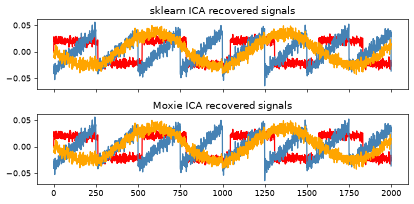

check,status,sklearn shape,moxie shape,max |diff|,max rel,tolerance,detail,tolerance reason
FastICA.fit_transform (S_),PASS,"(2000, 3)","(2000, 3)",2.43e-16,7.85e-12,"rtol=1e-07, atol=1e-08",,"same w_init, same fixed-point iteration; the iterates converge to tol=1e-4, so the result is a contraction of rounding differences (Jacobi SVD / mojo-linalg eigh vs LAPACK, reduction order) over the iterations"
mixing_,PASS,"(3, 3)","(3, 3)",3.13e-13,5.64e-15,"rtol=1e-07, atol=1e-08",,"same w_init, same fixed-point iteration; the iterates converge to tol=1e-4, so the result is a contraction of rounding differences (Jacobi SVD / mojo-linalg eigh vs LAPACK, reduction order) over the iterations"
components_,PASS,"(3, 3)","(3, 3)",1.25e-16,5.11e-15,"rtol=1e-07, atol=1e-08",,"same w_init, same fixed-point iteration; the iterates converge to tol=1e-4, so the result is a contraction of rounding differences (Jacobi SVD / mojo-linalg eigh vs LAPACK, reduction order) over the iterations"
whitening_,PASS,"(3, 3)","(3, 3)",4.86e-17,2.72e-15,"rtol=1e-10, atol=1e-12",,"economy SVD of the centered data, sign u *= sign(u[0]); no iteration involved"
mean_,PASS,"(3,)","(3,)",0,0,"rtol=1e-12, atol=1e-15",,2000-term column means; summation order
n_iter_,PASS,(),(),,,exact,0 mismatches,
"X == S_ @ mixing_.T + mean_ (example assert, Moxie)",PASS,"(2000, 3)","(2000, 3)",1.33e-14,6.04e-11,"rtol=1e-10, atol=1e-10",,exact algebraic identity; Float64 rounding of a 3-term product
PCA.fit_transform (H),PASS,"(2000, 3)","(2000, 3)",1.56e-14,2.4e-11,"rtol=1e-09, atol=1e-10",,Float64 Jacobi SVD vs LAPACK; same svd_flip rule
fastica() K,PASS,"(3, 3)","(3, 3)",4.86e-17,2.72e-15,"rtol=1e-10, atol=1e-12",,whitening matrix; no iteration
fastica() W,PASS,"(3, 3)","(3, 3)",2.89e-15,5.09e-15,"rtol=1e-07, atol=1e-08",,"same w_init, same fixed-point iteration; the iterates converge to tol=1e-4, so the result is a contraction of rounding differences (Jacobi SVD / mojo-linalg eigh vs LAPACK, reduction order) over the iterations"


In [4]:
mx = nb.results["ica_bss"]
moxie_nb.side_by_side(sklearn=A_, moxie=mx["mixing"])
fig, axes = plt.subplots(2, 1, figsize=(7, 3.5), dpi=60, sharex=True)
for ax, (title, data) in zip(axes, [("sklearn ICA recovered signals", S_), ("Moxie ICA recovered signals", mx["S_"])]):
    for sig, color in zip(data.T, ["red", "steelblue", "orange"]):
        ax.plot(sig, color=color)
    ax.set_title(title)
plt.tight_layout(); plt.show()

ICA = ("same w_init, same fixed-point iteration; the iterates converge to tol=1e-4, so the result is a contraction "
       "of rounding differences (Jacobi SVD / mojo-linalg eigh vs LAPACK, reduction order) over the iterations")
nb.compare("FastICA.fit_transform (S_)", S_, mx["S_"], rtol=1e-7, atol=1e-8, reason=ICA)
nb.compare("mixing_", A_, mx["mixing"], rtol=1e-7, atol=1e-8, reason=ICA)
nb.compare("components_", ica.components_, mx["components"], rtol=1e-7, atol=1e-8, reason=ICA)
nb.compare("whitening_", ica.whitening_, mx["whitening"], rtol=1e-10, atol=1e-12,
           reason="economy SVD of the centered data, sign u *= sign(u[0]); no iteration involved")
nb.compare("mean_", ica.mean_, mx["mean"], rtol=1e-12, atol=1e-15, reason="2000-term column means; summation order")
nb.compare("n_iter_", ica.n_iter_, mx["n_iter"][0], exact=True)
nb.compare("X == S_ @ mixing_.T + mean_ (example assert, Moxie)", X, mx["S_"] @ mx["mixing"].T + mx["mean"],
           rtol=1e-10, atol=1e-10, reason="exact algebraic identity; Float64 rounding of a 3-term product")
nb.compare("PCA.fit_transform (H)", H, mx["H"], rtol=1e-9, atol=1e-10, reason="Float64 Jacobi SVD vs LAPACK; same svd_flip rule")
nb.compare("fastica() K", sk["fn_K"], mx["fn_K"], rtol=1e-10, atol=1e-12, reason="whitening matrix; no iteration")
nb.compare("fastica() W", sk["fn_W"], mx["fn_W"], rtol=1e-7, atol=1e-8, reason=ICA)
nb.compare("fastica() S", sk["fn_S"], mx["fn_S"], rtol=1e-7, atol=1e-8, reason=ICA)
nb.compare("fastica() X_mean", sk["fn_mean"], mx["fn_mean"], rtol=1e-12, atol=1e-15, reason="column means")
nb.compare("fastica() n_iter", sk["fn_n_iter"], mx["fn_n_iter"][0], exact=True)
for name in ["deflation", "exp", "cube", "unit_eigh"]:
    nb.compare(f"{name}: fit_transform", sk[name + "_S"], mx[name + "_S"], rtol=1e-6, atol=1e-7, reason=ICA)
    nb.compare(f"{name}: n_iter_", sk[name + "_n_iter"], mx[name + "_n_iter"][0], exact=True)
    nb.compare(f"{name}: inverse_transform(transform(X[:50]))", sk[name + "_inverse"], mx[name + "_inverse"],
               rtol=1e-9, atol=1e-9, reason="round trip through components_ and mixing_ = pinv(components_)")
nb.compare("Float32 transform", sk["f32_S"], mx["f32_S"], rtol=2e-3, atol=2e-3,
           reason="Float32 fixed-point iterations stop at tol=1e-4; float32 rounding (~6e-8) is amplified "
                  "differently by LAPACK float32 SVD and Moxie's Float64-accumulated reductions")
nb.note("random_state=None", "ADAPTED", "Moxie cannot read NumPy's global RandomState; the identical draw is passed as w_init")
nb.report()
nb.assert_parity()